以下を行う。
```
Gaussian distribution
        ↓
   Generative Model
        ↓
digit image
```

device: cpu
alpha_bars[T]=0.0063527119345963


epoch    0 | loss = 0.981138


epoch   50 | loss = 0.260030


epoch  100 | loss = 0.247324


epoch  150 | loss = 0.248171


epoch  199 | loss = 0.206425


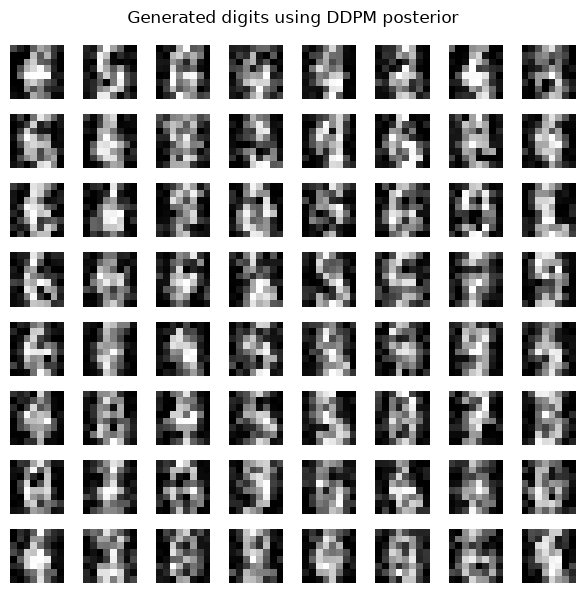

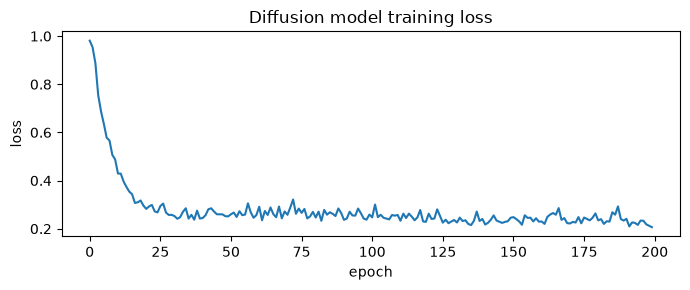

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from torch.utils.data import DataLoader, TensorDataset


# -----------------------
# setup
# -----------------------
device = "cuda" if torch.cuda.is_available() else "cpu"

torch.manual_seed(0)
np.random.seed(0)

print("device:", device)


# -----------------------
# data: sklearn digits
# -----------------------
digits = load_digits()

x = digits.data.astype("float32") / 16.0  # [0, 1]
x = x * 2.0 - 1.0                        # [-1, 1]

x_tensor = torch.tensor(x, dtype=torch.float32)

loader = DataLoader(
    TensorDataset(x_tensor),
    batch_size=256,
    shuffle=True,
)

data_dim = 64


# -----------------------
# linear diffusion schedule
# -----------------------
T = 500

betas = torch.linspace(
    1e-4,
    0.02,
    T,
    device=device,
)

alphas = 1.0 - betas

# alpha_bar_k = product_{s=0}^{k} alpha_s
alpha_bars = torch.cumprod(alphas, dim=0)

# alpha_bar_{k-1}
# k = 0 のときは alpha_bar_{-1} = 1 とみなす
alpha_bars_prev = torch.cat(
    [
        torch.ones(1, device=device),
        alpha_bars[:-1],
    ],
    dim=0,
)

print(f"alpha_bars[T]={alpha_bars[-1]}")

# -----------------------
# posterior parameters
#
# q(x_{k-1} | x_k, x_0)
#   = N(
#       posterior_mean_coef1[k] * x_0
#       + posterior_mean_coef2[k] * x_k,
#       posterior_variance[k] I
#     )
# -----------------------
posterior_variance = (
    betas
    * (1.0 - alpha_bars_prev)
    / (1.0 - alpha_bars)
)

posterior_mean_coef1 = (
    betas
    * torch.sqrt(alpha_bars_prev)
    / (1.0 - alpha_bars)
)

posterior_mean_coef2 = (
    torch.sqrt(alphas)
    * (1.0 - alpha_bars_prev)
    / (1.0 - alpha_bars)
)


# -----------------------
# timestep embedding
# -----------------------
class TimeEmbedding(nn.Module):
    def __init__(self, dim=64):
        super().__init__()

        if dim % 2 != 0:
            raise ValueError("TimeEmbedding dim must be even.")

        self.dim = dim

    def forward(self, k):
        half = self.dim // 2

        freqs = torch.exp(
            -np.log(10000.0)
            * torch.arange(
                half,
                device=k.device,
                dtype=torch.float32,
            )
            / half
        )

        args = k[:, None].float() * freqs[None, :]

        return torch.cat(
            [
                torch.sin(args),
                torch.cos(args),
            ],
            dim=1,
        )


# -----------------------
# noise prediction model
# epsilon_theta(x_k, k)
# -----------------------
class DiffusionModel(nn.Module):
    def __init__(
        self,
        data_dim=64,
        time_dim=64,
        hidden=256,
    ):
        super().__init__()

        self.time_emb = TimeEmbedding(time_dim)

        self.net = nn.Sequential(
            nn.Linear(data_dim + time_dim, hidden),
            nn.GELU(),

            nn.Linear(hidden, hidden),
            nn.GELU(),

            nn.Linear(hidden, hidden),
            nn.GELU(),

            nn.Linear(hidden, data_dim),
        )

    def forward(self, x_k, k):
        time_embedding = self.time_emb(k)

        model_input = torch.cat(
            [
                x_k,
                time_embedding,
            ],
            dim=1,
        )

        return self.net(model_input)


model = DiffusionModel(
    data_dim=data_dim,
).to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3,
)


# -----------------------
# utility:
# batchごとの時刻kに対応する値を取り出す
# -----------------------
def extract(values, k, x_shape):
    """
    values: shape [T]
    k:      shape [batch_size]
    return: shape [batch_size, 1, ..., 1]
    """
    batch_size = k.shape[0]

    out = values.gather(0, k)

    return out.reshape(
        batch_size,
        *((1,) * (len(x_shape) - 1)),
    )


# -----------------------
# forward diffusion
#
# q(x_k | x_0)
# x_k =
#   sqrt(alpha_bar_k) x_0
#   + sqrt(1-alpha_bar_k) epsilon
# -----------------------
def q_sample(x0, k, eps=None):
    if eps is None:
        eps = torch.randn_like(x0)

    sqrt_alpha_bar_k = extract(
        torch.sqrt(alpha_bars),
        k,
        x0.shape,
    )

    sqrt_one_minus_alpha_bar_k = extract(
        torch.sqrt(1.0 - alpha_bars),
        k,
        x0.shape,
    )

    x_k = (
        sqrt_alpha_bar_k * x0
        + sqrt_one_minus_alpha_bar_k * eps
    )

    return x_k


# -----------------------
# epsilon predictionからx_0を予測
#
# x_k =
#   sqrt(alpha_bar_k) x_0
#   + sqrt(1-alpha_bar_k) epsilon
#
# therefore
#
# x_0 =
#   (x_k - sqrt(1-alpha_bar_k) epsilon)
#   / sqrt(alpha_bar_k)
# -----------------------
def predict_x0_from_eps(x_k, k, eps_pred):
    sqrt_alpha_bar_k = extract(
        torch.sqrt(alpha_bars),
        k,
        x_k.shape,
    )

    sqrt_one_minus_alpha_bar_k = extract(
        torch.sqrt(1.0 - alpha_bars),
        k,
        x_k.shape,
    )

    x0_pred = (
        x_k
        - sqrt_one_minus_alpha_bar_k * eps_pred
    ) / sqrt_alpha_bar_k

    return x0_pred


# -----------------------
# true posterior
#
# q(x_{k-1} | x_k, x_0)
# -----------------------
def q_posterior(x0, x_k, k):
    coef1 = extract(
        posterior_mean_coef1,
        k,
        x_k.shape,
    )

    coef2 = extract(
        posterior_mean_coef2,
        k,
        x_k.shape,
    )

    variance = extract(
        posterior_variance,
        k,
        x_k.shape,
    )

    posterior_mean = (
        coef1 * x0
        + coef2 * x_k
    )

    return posterior_mean, variance


# -----------------------
# model posterior
#
# p_theta(x_{k-1} | x_k)
# -----------------------
def p_mean_variance(model, x_k, k):
    eps_pred = model(x_k, k)

    x0_pred = predict_x0_from_eps(
        x_k=x_k,
        k=k,
        eps_pred=eps_pred,
    )

    # 数値的不安定性を抑えるため、
    # 学習データの範囲[-1, 1]に制限する
    x0_pred = torch.clamp(
        x0_pred,
        -1.0,
        1.0,
    )

    posterior_mean, posterior_var = q_posterior(
        x0=x0_pred,
        x_k=x_k,
        k=k,
    )

    return posterior_mean, posterior_var, x0_pred


# -----------------------
# training
# -----------------------
n_epochs = 200
losses = []

model.train()

for epoch in range(n_epochs):
    total_loss = 0.0

    for (x0,) in loader:
        x0 = x0.to(device)

        batch_size = x0.shape[0]

        # k = 0, ..., T-1
        k = torch.randint(
            low=0,
            high=T,
            size=(batch_size,),
            device=device,
        )

        eps = torch.randn_like(x0)

        x_k = q_sample(
            x0=x0,
            k=k,
            eps=eps,
        )

        eps_pred = model(
            x_k,
            k,
        )

        # simple DDPM loss
        loss = ((eps_pred - eps) ** 2).mean()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    epoch_loss = total_loss / len(loader)
    losses.append(epoch_loss)

    if epoch % 50 == 0 or epoch == n_epochs - 1:
        print(
            f"epoch {epoch:4d} | "
            f"loss = {epoch_loss:.6f}"
        )


# -----------------------
# one reverse step
#
# x_{k-1} ~ p_theta(x_{k-1} | x_k)
# -----------------------
@torch.no_grad()
def p_sample(model, x_k, k):
    posterior_mean, posterior_var, x0_pred = p_mean_variance(
        model=model,
        x_k=x_k,
        k=k,
    )

    noise = torch.randn_like(x_k)

    # k = 0ではx_0を生成するため、
    # posterior varianceを加えない
    nonzero_mask = (
        (k != 0)
        .float()
        .reshape(
            k.shape[0],
            *((1,) * (len(x_k.shape) - 1)),
        )
    )

    x_prev = (
        posterior_mean
        + nonzero_mask
        * torch.sqrt(
            torch.clamp(
                posterior_var,
                min=1e-20,
            )
        )
        * noise
    )

    return x_prev, x0_pred


# -----------------------
# reverse diffusion sampling
# -----------------------
@torch.no_grad()
def sample_digits(model, n_samples=64):
    model.eval()

    # x_{T-1} ~ N(0, I)
    x = torch.randn(
        n_samples,
        data_dim,
        device=device,
    )

    for k_value in reversed(range(T)):
        k_batch = torch.full(
            size=(n_samples,),
            fill_value=k_value,
            device=device,
            dtype=torch.long,
        )

        x, _ = p_sample(
            model=model,
            x_k=x,
            k=k_batch,
        )

    # [-1, 1] -> [0, 1]
    x = (x + 1.0) / 2.0

    x = torch.clamp(
        x,
        0.0,
        1.0,
    )

    return x.cpu().numpy()


generated = sample_digits(
    model,
    n_samples=64,
)


# -----------------------
# plot generated digits
# -----------------------
fig, axes = plt.subplots(
    8,
    8,
    figsize=(6, 6),
)

for i, ax in enumerate(axes.ravel()):
    ax.imshow(
        generated[i].reshape(8, 8),
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    ax.axis("off")

plt.suptitle(
    "Generated digits using DDPM posterior"
)

plt.tight_layout()
plt.show()


# -----------------------
# plot loss
# -----------------------
plt.figure(figsize=(7, 3))

plt.plot(losses)

plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("Diffusion model training loss")

plt.tight_layout()
plt.show()